## Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

## Part I – Image, operations and kernels
Set `IMAGE_PATH = 'your_image.jpg'` to use your own picture (needs Pillow); `None` uses a synthetic building facade.

In [2]:
IMAGE_PATH = None  # e.g. 'building.jpg'

def make_synthetic_building(size=128):
    """Grayscale 'facade' with crisp horizontal/vertical edges + gradient."""
    img = np.full((size, size), 200.0)
    img += np.linspace(-30, 30, size)[None, :]
    for r in range(8, size - 8, 24):
        for c in range(8, size - 8, 24):
            img[r:r + 14, c:c + 14] = 40.0
            img[r + 14:r + 17, c - 2:c + 16] = 120.0
    img[:, ::24] = 90.0
    img[::32, :] = 90.0
    return np.clip(img, 0, 255) / 255.0


def load_image(path, max_side=256):
    if path is None:
        return make_synthetic_building()
    from PIL import Image
    im = Image.open(path).convert("L")
    im.thumbnail((max_side, max_side))
    return np.asarray(im, dtype=np.float64) / 255.0

In [3]:
def conv2d(img, kernel):
    """'Same' 2-D cross-correlation (what DL frameworks call convolution), zero padding."""
    kh, kw = kernel.shape
    padded = np.pad(img, ((kh // 2, kh // 2), (kw // 2, kw // 2)), mode="constant")
    windows = sliding_window_view(padded, (kh, kw))
    return np.einsum("ijkl,kl->ij", windows, kernel)


def relu(x):
    return np.maximum(0.0, x)


def pool2x2(x, mode="max"):
    h, w = (x.shape[0] // 2) * 2, (x.shape[1] // 2) * 2
    blocks = x[:h, :w].reshape(h // 2, 2, w // 2, 2)
    return blocks.max(axis=(1, 3)) if mode == "max" else blocks.mean(axis=(1, 3))


KERNELS = {

    "Horizontal Edge (Sobel)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float),
    "Vertical Edge (Sobel)":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float),
    "Sharpen":                 np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float),
    "Box Blur":                np.ones((3, 3), dtype=float) / 9.0,
    "Emboss":                  np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=float),
}


def run_pipeline(img):
    out = {}
    for name, k in KERNELS.items():
        a = conv2d(img, k)
        b = relu(a)
        c = pool2x2(b, "max")
        d = pool2x2(b, "avg")
        out[name] = (a, b, c, d)
    return out

### 5 × 4 visualization grid (Stages A–D)

[Part I] Grid saved to: /content/cnn_grid_5x4.png


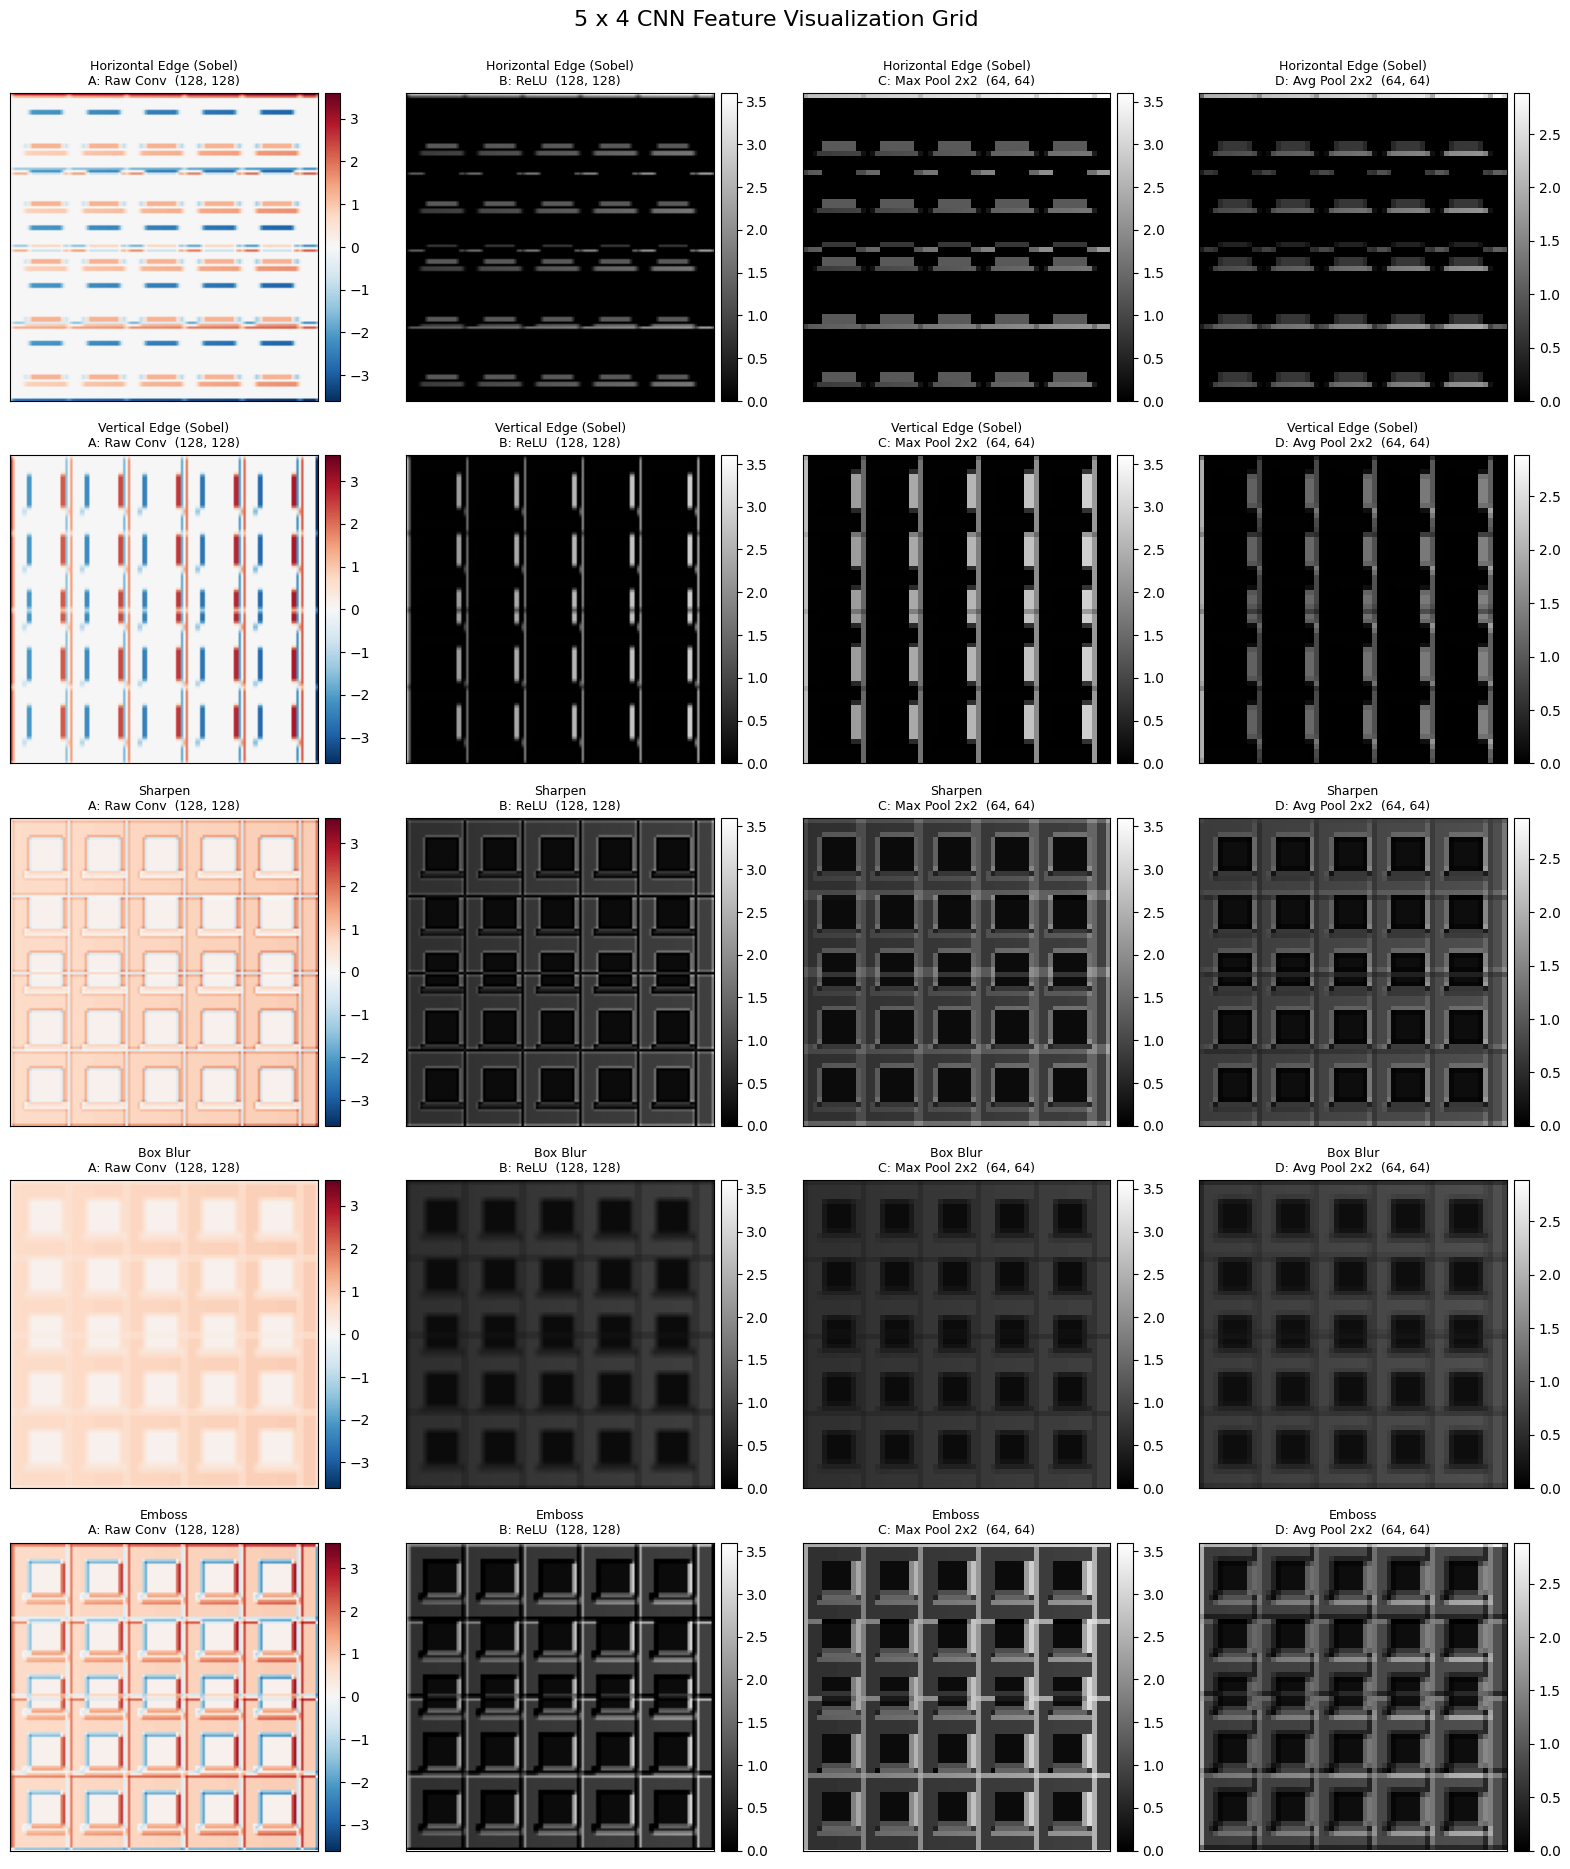

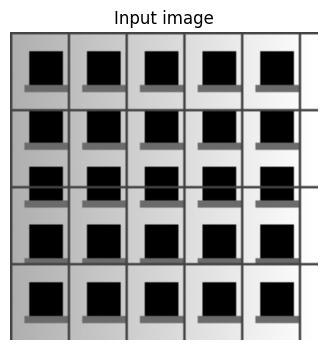

In [4]:
def plot_grid(img, results, save_path="cnn_grid_5x4.png"):
    titles = ["A: Raw Conv", "B: ReLU", "C: Max Pool 2x2", "D: Avg Pool 2x2"]
    names = list(results.keys())

    amax = max(np.abs(results[n][0]).max() for n in names)
    bmax = max(results[n][1].max() for n in names)
    cmax = max(results[n][2].max() for n in names)
    dmax = max(results[n][3].max() for n in names)
    scales = [(-amax, amax, "RdBu_r"), (0, bmax, "gray"), (0, cmax, "gray"), (0, dmax, "gray")]

    fig, axes = plt.subplots(5, 4, figsize=(16, 19))
    for r, n in enumerate(names):
        for c in range(4):
            ax = axes[r, c]
            vmin, vmax, cmap = scales[c]
            im = ax.imshow(results[n][c], cmap=cmap, vmin=vmin, vmax=vmax)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"{n}\n{titles[c]}  {results[n][c].shape}", fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
    fig.suptitle("5 x 4 CNN Feature Visualization Grid", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(save_path, dpi=120)
    print(f"[Part I] Grid saved to: {os.path.abspath(save_path)}")


    fig2, ax2 = plt.subplots(figsize=(4, 4))
    ax2.imshow(img, cmap="gray"); ax2.set_title("Input image"); ax2.axis("off")
    fig2.savefig("input_image.png", dpi=120)
    plt.show()

img = load_image(IMAGE_PATH)
results = run_pipeline(img)
plot_grid(img, results)

## Part II – Parameter audit (hand calculation vs framework)

`Params per conv layer = (Kh × Kw × Cin + 1) × Cout`

In [5]:
def conv_params(k, cin, cout):
    return (k * k * cin + 1) * cout


def dense_params(nin, nout):
    return (nin + 1) * nout


def manual_audit():
    rows = {}
    for name, k in (("Model A (3x3, MaxPool)", 3), ("Model B (5x5, AvgPool)", 5)):
        c1 = conv_params(k, 3, 5)
        c2 = conv_params(k, 5, 10)
        fc = dense_params(10, 10)
        rows[name] = (c1, c2, fc, c1 + c2 + fc)
        print(f"\n{name}")
        print(f"  Conv1 = ({k}*{k}*3 + 1) * 5  = {c1}")
        print(f"  Conv2 = ({k}*{k}*5 + 1) * 10 = {c2}")
        print(f"  Dense = (10 + 1) * 10        = {fc}")
        print(f"  TOTAL                        = {rows[name][3]}")
    return rows


def framework_counts():
    """Return {model_name: param_count} from a real framework, or None."""
    try:
        import torch
        import torch.nn as nn

        def build(k, pool):
            p = nn.MaxPool2d(2, 2) if pool == "max" else nn.AvgPool2d(2, 2)
            return nn.Sequential(
                nn.Conv2d(3, 5, k, padding=k // 2), nn.ReLU(), p,
                nn.Conv2d(5, 10, k, padding=k // 2), nn.ReLU(), p,
                nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(10, 10))
        out = {}
        for name, m in (("Model A (3x3, MaxPool)", build(3, "max")),
                        ("Model B (5x5, AvgPool)", build(5, "avg"))):
            print(f"\n--- PyTorch summary: {name} ---")
            x = torch.zeros(1, 3, 32, 32)
            for layer in m:
                x = layer(x)
                n = sum(p.numel() for p in layer.parameters())
                print(f"{layer.__class__.__name__:<18} out={tuple(x.shape)!s:<18} params={n}")
            out[name] = sum(p.numel() for p in m.parameters())
            print(f"Total trainable params: {out[name]}")
        return out
    except Exception as e:
        print(f"(PyTorch unavailable: {type(e).__name__})")
    try:
        os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
        from tensorflow import keras
        from tensorflow.keras import layers

        def build(k, pool):
            P = layers.MaxPooling2D if pool == "max" else layers.AveragePooling2D
            return keras.Sequential([
                keras.Input((32, 32, 3)),
                layers.Conv2D(5, k, padding="same", activation="relu"), P(2, 2),
                layers.Conv2D(10, k, padding="same", activation="relu"), P(2, 2),
                layers.GlobalAveragePooling2D(), layers.Dense(10, activation="softmax")])
        out = {}
        for name, m in (("Model A (3x3, MaxPool)", build(3, "max")),
                        ("Model B (5x5, AvgPool)", build(5, "avg"))):
            print(f"\n--- Keras summary: {name} ---")
            m.summary()
            out[name] = m.count_params()
        return out
    except Exception as e:
        print(f"(TensorFlow unavailable: {type(e).__name__})")
        return None


def print_manual_summary():
    """Fallback 'model.summary()'-style table when no DL framework is installed."""
    for name, k in (("Model A (3x3, MaxPool)", 3), ("Model B (5x5, AvgPool)", 5)):
        print(f"\n--- Manual summary table: {name} ---")
        print(f"{'Layer':<28}{'Output shape':<18}{'Params':>8}")
        print(f"{'Input':<28}{'(32,32,3)':<18}{0:>8}")
        print(f"{f'Conv2D {k}x{k}, 5 (same)':<28}{'(32,32,5)':<18}{conv_params(k,3,5):>8}")
        print(f"{'Pool 2x2/2':<28}{'(16,16,5)':<18}{0:>8}")
        print(f"{f'Conv2D {k}x{k}, 10 (same)':<28}{'(16,16,10)':<18}{conv_params(k,5,10):>8}")
        print(f"{'Pool 2x2/2':<28}{'(8,8,10)':<18}{0:>8}")
        print(f"{'GlobalAveragePooling':<28}{'(10,)':<18}{0:>8}")
        print(f"{'Dense 10':<28}{'(10,)':<18}{dense_params(10,10):>8}")

In [6]:
rows = manual_audit()
fw = framework_counts()
if fw is None:
    print('\n(torch/tensorflow not installed - manual summary shown)')
    print_manual_summary()
else:
    for name, total in fw.items():
        print(name, 'MATCH' if total == rows[name][3] else 'MISMATCH')
    print('\nVERIFIED: framework counts match hand calculations.')


Model A (3x3, MaxPool)
  Conv1 = (3*3*3 + 1) * 5  = 140
  Conv2 = (3*3*5 + 1) * 10 = 460
  Dense = (10 + 1) * 10        = 110
  TOTAL                        = 710

Model B (5x5, AvgPool)
  Conv1 = (5*5*3 + 1) * 5  = 380
  Conv2 = (5*5*5 + 1) * 10 = 1260
  Dense = (10 + 1) * 10        = 110
  TOTAL                        = 1750

--- PyTorch summary: Model A (3x3, MaxPool) ---
Conv2d             out=(1, 5, 32, 32)     params=140
ReLU               out=(1, 5, 32, 32)     params=0
MaxPool2d          out=(1, 5, 16, 16)     params=0
Conv2d             out=(1, 10, 16, 16)    params=460
ReLU               out=(1, 10, 16, 16)    params=0
MaxPool2d          out=(1, 10, 8, 8)      params=0
AdaptiveAvgPool2d  out=(1, 10, 1, 1)      params=0
Flatten            out=(1, 10)            params=0
Linear             out=(1, 10)            params=110
Total trainable params: 710

--- PyTorch summary: Model B (5x5, AvgPool) ---
Conv2d             out=(1, 5, 32, 32)     params=380
ReLU               out=(1,

## Part III – Evidence for the viva questions
Use these numbers and the grid above to write your answers to Q1–Q5.

In [7]:
def part3(results, rows):
    print("\n" + "=" * 70 + "\nPART III - EVIDENCE FOR VIVA ANSWERS\n" + "=" * 70)

    # Q1: ReLU blackout
    print("\nQ1: Fraction of pixels zeroed by ReLU (negative after convolution)")
    for n, (a, b, _, _) in results.items():
        print(f"  {n:<26} negative: {np.mean(a < 0)*100:5.1f}%   zero after ReLU: {np.mean(b == 0)*100:5.1f}%")
    x = np.array([-2.0, -0.5, 0.0, 1.0, 3.0])
    print("  Sample x          :", x)
    print("  ReLU              :", relu(x))
    print("  LeakyReLU(a=0.1)  :", np.where(x > 0, x, 0.1 * x))
    print("  Sigmoid           :", np.round(1 / (1 + np.exp(-x)), 4))

    # Q2: Max vs Avg pooling
    print("\nQ2: Peak response retained (max over feature map)")
    for n, (_, b, c, d) in results.items():
        print(f"  {n:<26} ReLU max={b.max():7.3f}  MaxPool max={c.max():7.3f}  AvgPool max={d.max():7.3f}")
    patch = np.array([[255, 255], [255, 0]], dtype=float)
    print("  White-bg/dark-ink patch [[255,255],[255,0]]: max =", patch.max(), " avg =", patch.mean(),
          "-> max pooling erases the ink stroke; avg pooling keeps a trace (191.25).")
    print("  Inverted view (ink=high): max pooling preserves strokes best, so invert first.")

    # Q3: parameter explosion
    a_tot, b_tot = rows["Model A (3x3, MaxPool)"][3], rows["Model B (5x5, AvgPool)"][3]
    a_conv, b_conv = a_tot - 110, b_tot - 110
    print(f"\nQ3: Model A total = {a_tot}, Model B total = {b_tot}")
    print(f"  Increase (total)      : {(b_tot - a_tot)/a_tot*100:.2f}%")
    print(f"  Increase (conv only)  : {(b_conv - a_conv)/a_conv*100:.2f}%")
    print("  Receptive field: two stacked 3x3 layers (stride 1) = 5x5 -> 2 layers needed.")
    for C in (5, 10, 64):
        s5, s33 = 25 * C * C, 2 * 9 * C * C
        print(f"  C->C channels, C={C:<3}: 5x5 weights={s5:<7} 2x(3x3) weights={s33:<7} saved={s5-s33} ({(s5-s33)/s5*100:.0f}%)")
    one = conv_params(5, 3, 5)
    two = conv_params(3, 3, 5) + conv_params(3, 5, 5)
    print(f"  Model-B Conv1 (3->5): single 5x5 = {one}, stacked 3x3 (3->5->5) = {two}, saved = {one-two}")


    print("\nQ4: Conv->ReLU->MaxPool vs Conv->MaxPool->ReLU")
    for patch in (np.array([[-3.0, -1.0], [-2.0, 4.0]]), np.array([[-3.0, -1.0], [-2.0, -5.0]])):
        p1 = np.max(relu(patch))
        p2 = relu(np.max(patch))
        print(f"  patch={patch.tolist()}  ReLU->Max={p1}  Max->ReLU={p2}  identical={p1 == p2}")
    a, b, c, _ = results["Emboss"]
    alt = relu(pool2x2(a, "max"))
    print("  Full-image check (Emboss): identical =", np.allclose(c, alt))
    print("  Efficiency: Max->ReLU applies ReLU on 4x fewer elements (H*W/4 vs H*W).")
    print("  Caveat: NOT commutative with Average pooling (mean of ReLU != ReLU of mean).")
    ap = np.array([[-3.0, 1.0], [-2.0, 2.0]])
    print(f"  Avg example {ap.tolist()}: mean(ReLU)={relu(ap).mean()}  ReLU(mean)={relu(ap.mean())}")

    print("\nQ5: Filter collapse - see report answers: (1) identical/poor init or tiny init scale ->"
          " use He/Kaiming random init + BatchNorm; (2) dead ReLUs / too-high LR ->"
          " lower LR, LeakyReLU, Adam + warmup.")

part3(results, rows)


PART III - EVIDENCE FOR VIVA ANSWERS

Q1: Fraction of pixels zeroed by ReLU (negative after convolution)
  Horizontal Edge (Sobel)    negative:   9.8%   zero after ReLU:  86.8%
  Vertical Edge (Sobel)      negative:  11.0%   zero after ReLU:  39.1%
  Sharpen                    negative:  13.9%   zero after ReLU:  13.9%
  Box Blur                   negative:   0.0%   zero after ReLU:   0.0%
  Emboss                     negative:  15.2%   zero after ReLU:  15.2%
  Sample x          : [-2.  -0.5  0.   1.   3. ]
  ReLU              : [0. 0. 0. 1. 3.]
  LeakyReLU(a=0.1)  : [-0.2  -0.05  0.    1.    3.  ]
  Sigmoid           : [0.1192 0.3775 0.5    0.7311 0.9526]

Q2: Peak response retained (max over feature map)
  Horizontal Edge (Sobel)    ReLU max=  3.600  MaxPool max=  3.600  AvgPool max=  2.883
  Vertical Edge (Sobel)      ReLU max=  2.921  MaxPool max=  2.921  AvgPool max=  1.972
  Sharpen                    ReLU max=  2.708  MaxPool max=  2.708  AvgPool max=  1.803
  Box Blur        